# Settimana 1 · Algebra lineare con NumPy

Questo notebook accompagna la playlist **Essence of Linear Algebra** di 3Blue1Brown (YouTube).
Ogni sezione dice quale video guardare prima; poi rifai in NumPy quello che hai visto.

**Come si usa**
1. Esegui la cella di *Setup* qui sotto (`Shift + Invio`). Va rieseguita ogni volta che riapri il notebook.
2. In ogni esercizio sostituisci i `None` con il tuo codice.
3. Esegui la cella **Controllo** che segue: ✅ giusto · ❌ da rivedere · ⏳ non ancora svolto.
4. Bloccato? Le soluzioni sono nel notebook `settimana1_soluzioni.ipynb`, ma prova almeno 10 minuti prima di guardarle.

**Installazione** (una volta sola, dal terminale):
```
pip install numpy matplotlib notebook
jupyter notebook
```

In [1]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.2.2 -> 26.2.2
[notice] To update, run: C:\Users\emanuele\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


## Setup

In [5]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

def controlla(nome, valore, atteso, tol=1e-6):
    """Confronta il tuo risultato con quello atteso."""
    if valore is None:
        print(f"⏳ {nome}: non ancora svolto")
        return
    try:
        v = np.asarray(valore, dtype=float)
        a = np.asarray(atteso, dtype=float)
        ok = v.shape == a.shape and np.allclose(v, a, atol=tol)
    except Exception:
        ok = False
    if ok:
        print(f"✅ {nome}")
    else:
        print(f"❌ {nome}: hai ottenuto {valore!r}")

print("Setup completato, NumPy", np.__version__)

Setup completato, NumPy 1.26.0


## 0. Le basi di NumPy (nessun video)

L'oggetto centrale di NumPy è l'**array**: una griglia di numeri. Esegui le celle e leggi l'output.
Tre cose da ricordare sempre:
- `.shape` ti dice la forma (righe, colonne): controllala spesso, la maggior parte dei bug sono forme sbagliate.
- `*` moltiplica **elemento per elemento**; `@` fa il **prodotto matriciale**.
- Le operazioni si applicano a tutto l'array insieme, senza cicli `for`.

In [6]:
v = np.array([3, 1])           # vettore
A = np.array([[2, 0],
              [0, 3]])         # matrice 2x2

print("v =", v, "  shape:", v.shape)
print("A =\n", A, "\n  shape:", A.shape)
print("A * A (elemento per elemento) =\n", A * A)
print("A @ A (prodotto matriciale)   =\n", A @ A)
print("A @ v =", A @ v)

v = [3 1]   shape: (2,)
A =
 [[2 0]
 [0 3]] 
  shape: (2, 2)
A * A (elemento per elemento) =
 [[4 0]
 [0 9]]
A @ A (prodotto matriciale)   =
 [[4 0]
 [0 9]]
A @ v = [6 3]


In [7]:
# Indicizzazione: righe e colonne
B = np.array([[1, 2, 3],
              [4, 5, 6]])
print("elemento riga 0, colonna 2:", B[0, 2])
print("riga 1:   ", B[1])
print("colonna 0:", B[:, 0])
print("trasposta:\n", B.T)
print("somma per colonna (axis=0):", B.sum(axis=0))
print("somma per riga    (axis=1):", B.sum(axis=1))

elemento riga 0, colonna 2: 3
riga 1:    [4 5 6]
colonna 0: [1 4]
trasposta:
 [[1 4]
 [2 5]
 [3 6]]
somma per colonna (axis=0): [5 7 9]
somma per riga    (axis=1): [ 6 15]


## 1. Vettori e combinazioni lineari
📺 Capitoli 1–2: *Vectors* e *Linear combinations, span, and basis vectors*

**1.1** Crea i vettori **v** = (3, 1) e **w** = (−1, 2).

In [8]:
v = np.array([3,1])
w = np.array([-1,2])

In [9]:
# Controllo 1.1
controlla("v", v, [3, 1])
controlla("w", w, [-1, 2])

✅ v
✅ w


**1.2** Calcola `s` = **v** + **w** e `d` = 2**v** − 3**w**.

In [10]:
s = v+w
d = 2*v-3*w

In [11]:
# Controllo 1.2
controlla("s = v + w", s, [2, 3])
controlla("d = 2v - 3w", d, [9, -4])

✅ s = v + w
✅ d = 2v - 3w


**1.3** Calcola la lunghezza (norma) di **v** in due modi:
`lung_mano` con la formula √(x² + y²) usando `np.sqrt` e `np.sum`, e `lung_np` con `np.linalg.norm`.

In [12]:
lung_mano = np.sqrt(np.sum(v**2))
lung_np = np.linalg.norm(v)

In [13]:
# Controllo 1.3
controlla("lunghezza a mano", lung_mano, np.sqrt(10))
controlla("lunghezza con linalg.norm", lung_np, np.sqrt(10))

✅ lunghezza a mano
✅ lunghezza con linalg.norm


**1.4** Trova i numeri `a` e `b` tali che a·**v** + b·**w** = (5, 4).
Per ora ragiona a mano o per tentativi (sono interi piccoli); nella sezione 5 lo risolverai con NumPy.

In [14]:
a = 2
b = 1

In [15]:
# Controllo 1.4
risultato = None if a is None or b is None else a * v + b * w
controlla("a·v + b·w = (5, 4)", risultato, [5, 4])

✅ a·v + b·w = (5, 4)


## 2. Matrici come trasformazioni lineari
📺 Capitolo 3: *Linear transformations and matrices*

L'idea chiave del video: **le colonne di una matrice sono i punti dove finiscono î = (1, 0) e ĵ = (0, 1)**.
`np.column_stack([col1, col2])` costruisce una matrice a partire dalle sue colonne.

**2.1** Costruisci `R`, la rotazione di 90° in senso antiorario: î finisce in (0, 1) e ĵ in (−1, 0).

**2.2** Costruisci `S`, lo *shear* (taglio) del video: î resta in (1, 0) e ĵ finisce in (1, 1).

In [16]:
R = np.column_stack([[0,1],[-1,0]])
S = np.column_stack([[1,0],[1,1]])

In [17]:
# Controllo 2.1 e 2.2
controlla("R (rotazione 90°)", R, [[0, -1], [1, 0]])
controlla("S (shear)", S, [[1, 1], [0, 1]])

✅ R (rotazione 90°)
✅ S (shear)


**2.3** Applica la rotazione `R` al vettore **v**.

In [18]:
v_ruotato = R@v

In [19]:
# Controllo 2.3
controlla("R @ v", v_ruotato, [-1, 3])

✅ R @ v


**2.4** Il video dice che `S @ v` è uguale a *v[0] volte la prima colonna di S + v[1] volte la seconda colonna*.
Calcola `combo` in questo modo, usando `S[:, 0]` e `S[:, 1]` e senza `@`, e verifica che coincida con `S @ v`.

In [20]:
combo = v[0]*S[:,0]+v[1]*S[:,1]

In [21]:
# Controllo 2.4
controlla("combinazione delle colonne", combo, [4, 1])
if combo is not None:
    print("Coincide con S @ v?", np.allclose(combo, S @ v))

✅ combinazione delle colonne
Coincide con S @ v? True


## 3. Composizione di trasformazioni
📺 Capitolo 4: *Matrix multiplication as composition*

`R @ S` significa **prima** S, **poi** R: si legge da destra a sinistra, come le funzioni f(g(x)).

**3.1** Calcola `RS` = R·S e `SR` = S·R. Poi metti in `uguali` il risultato di `np.allclose(RS, SR)`.

In [22]:
RS =R@S
SR =S@R
uguali = np.allclose(RS,SR)

In [23]:
# Controllo 3.1
controlla("R @ S", RS, [[0, -1], [1, 1]])
controlla("S @ R", SR, [[1, -1], [1, 0]])
controlla("l'ordine conta (uguali deve essere False)", uguali, False)

✅ R @ S
✅ S @ R
✅ l'ordine conta (uguali deve essere False)


**3.2** Verifica che applicare S e poi R a **v** sia come applicare direttamente la matrice composta:
calcola `passo_passo` = R·(S·**v**) e `composta` = (R·S)·**v**.

In [24]:
passo_passo = R@(S@v)
composta = (R@S)@v

In [25]:
# Controllo 3.2
controlla("R @ (S @ v)", passo_passo, [-1, 4])
controlla("(R @ S) @ v", composta, [-1, 4])

✅ R @ (S @ v)
✅ (R @ S) @ v


## 4. Il determinante
📺 Capitolo 6: *The determinant*

Il determinante dice **di quanto una trasformazione moltiplica le aree**. Se è 0, lo spazio viene schiacciato su una retta (o un punto).

**4.1** Calcola con `np.linalg.det` il determinante di `R`, `S` e della matrice di "stiramento" `D` qui sotto.

In [26]:
D = np.array([[2, 0],
              [0, 3]])   # allunga x di 2 e y di 3

In [27]:
det_R = np.linalg.det(R)
det_S = np.linalg.det(S)
det_D = np.linalg.det(D)

In [28]:
# Controllo 4.1
controlla("det(R)", det_R, 1)
controlla("det(S)", det_S, 1)
controlla("det(D)", det_D, 6)
print("Rotazione e shear non cambiano le aree; D le moltiplica per 6.")

✅ det(R)
✅ det(S)
✅ det(D)
Rotazione e shear non cambiano le aree; D le moltiplica per 6.


**4.2** La matrice `M` qui sotto ha la seconda colonna uguale al doppio della prima.
Prevedi il suo determinante, poi calcolalo in `det_M`.

In [29]:
M = np.array([[1, 2],
              [2, 4]])

In [30]:
det_M = 0

In [31]:
# Controllo 4.2
controlla("det(M)", det_M, 0)

✅ det(M)


**4.3** Proprietà del video: det(A·B) = det(A)·det(B). Con `D` e `N` (sotto) calcola
`det_prodotto` = det(D·N) e `prodotto_det` = det(D)·det(N).

In [32]:
N = np.array([[1, 2],
              [3, 4]])

In [33]:
det_prodotto = np.linalg.det(D@N)
prodotto_det = np.linalg.det(D)*np.linalg.det(N)

In [34]:
# Controllo 4.3
controlla("det(D @ N)", det_prodotto, -12)
controlla("det(D) * det(N)", prodotto_det, -12)

✅ det(D @ N)
✅ det(D) * det(N)


## 5. Sistemi lineari, inversa e rango
📺 Capitoli 7–8: *Inverse matrices, column space and null space* e *Nonsquare matrices*

Ricordi l'esercizio 1.4? Trovare a e b con a·**v** + b·**w** = (5, 4) è il sistema A·x = b,
dove le colonne di A sono **v** e **w**.

**5.1** Costruisci `A` con colonne **v** e **w**, poi risolvi il sistema con `np.linalg.solve(A, b_vec)`.

In [35]:
b_vec = np.array([5, 4])

In [36]:
A = np.column_stack([v,w])
x = np.linalg.solve(A,b_vec)

In [37]:
# Controllo 5.1
controlla("A", A, [[3, -1], [1, 2]])
controlla("soluzione x = (a, b)", x, [2, 1])

✅ A
✅ soluzione x = (a, b)


**5.2** Calcola l'inversa `A_inv` con `np.linalg.inv`, poi verifica che `A @ A_inv` sia la matrice identità
(in NumPy: `np.eye(2)`). Metti il prodotto in `identita`.

In [38]:
A_inv = np.linalg.inv(A)
identita = A@A_inv

In [39]:
# Controllo 5.2
controlla("A_inv", A_inv, np.array([[2, 1], [-1, 3]]) / 7)
controlla("A @ A_inv = I", identita, np.eye(2))

✅ A_inv
✅ A @ A_inv = I


**5.3** Il **rango** è la dimensione dello spazio colonne (quante "direzioni indipendenti" produce la matrice).
Calcola il rango di `A` e di `M` con `np.linalg.matrix_rank`.

In [40]:
rango_A = np.linalg.matrix_rank(A)
rango_M = np.linalg.matrix_rank(M)

In [41]:
# Controllo 5.3
controlla("rango di A", rango_A, 2)
controlla("rango di M", rango_M, 1)
print("M schiaccia il piano su una retta: per questo il suo determinante è 0.")

✅ rango di A
✅ rango di M
M schiaccia il piano su una retta: per questo il suo determinante è 0.


## 6. Prodotto scalare
📺 Capitolo 9: *Dot products and duality*

Nel machine learning il prodotto scalare è ovunque: misura quanto due vettori "vanno nella stessa direzione".

**6.1** Calcola il prodotto scalare tra **v** e **w** in `prod` (usa `@` oppure `np.dot`).

In [42]:
prod = np.dot(v,w)

In [43]:
# Controllo 6.1
controlla("v · w", prod, -1)

✅ v · w


**6.2** L'angolo tra due vettori: cos θ = (p·q) / (|p| |q|).
Calcola `coseno` tra p = (1, 0) e q = (1, 1), poi l'angolo in gradi `angolo` con `np.arccos` e `np.degrees`.

In [44]:
p = np.array([1, 0])
q = np.array([1, 1])

In [45]:
coseno = np.dot(p,q)/(np.linalg.norm(p)*np.linalg.norm(q))
angolo = np.degrees(np.arccos(coseno))

In [46]:
# Controllo 6.2
controlla("coseno", coseno, 1 / np.sqrt(2))
controlla("angolo in gradi", angolo, 45)

✅ coseno
✅ angolo in gradi


**6.3** La proiezione di **v** sulla direzione di u = (1, 1) è ((v·u) / (u·u)) · u. Calcolala in `proiezione`.

proiezione = |v| · cos θ · u/|u|
           = |v| · (u·v)/(|u|·|v|) · u/|u|
           = (u·v) / (|u|·|u|) · u        ← |v| si semplifica
           = (u·v) / (u·u) · u

In [47]:
u = np.array([1, 1])

In [48]:
proiezione = (np.dot(v,u))/(np.dot(u,u))*u

In [49]:
# Controllo 6.3
controlla("proiezione di v su u", proiezione, [2, 2])

✅ proiezione di v su u


## 7. Cambio di base
📺 Capitolo 13: *Change of basis*

Nel video, Jennifer usa come vettori di base b₁ = (2, 1) e b₂ = (−1, 1).
La matrice `P` con colonne b₁ e b₂ traduce **dal linguaggio di Jennifer al nostro**.

**7.1** Costruisci `P`. Poi traduci nelle nostre coordinate il vettore che Jennifer chiama (−1, 2).

**7.2** Fai il contrario: il nostro vettore (3, 2), come lo chiama Jennifer? (Suggerimento: `np.linalg.solve`.)

In [58]:
P = np.column_stack([[2,1],[-1,1]])
nostro = P@(np.array([-1,2]))
di_jennifer = np.linalg.inv(P)@(np.array([3,2]))

In [59]:
# Controllo 7.1 e 7.2
controlla("P", P, [[2, -1], [1, 1]])
controlla("(-1, 2) di Jennifer nelle nostre coordinate", nostro, [-4, 1])
controlla("(3, 2) nelle coordinate di Jennifer", di_jennifer, [5 / 3, 1 / 3])

✅ P
✅ (-1, 2) di Jennifer nelle nostre coordinate
✅ (3, 2) nelle coordinate di Jennifer


## 8. Autovettori e autovalori
📺 Capitolo 14: *Eigenvectors and eigenvalues*

Un autovettore è un vettore che la trasformazione **non ruota**: lo allunga o accorcia soltanto,
di un fattore λ (l'autovalore). In formula: E·x = λ·x.

**8.1** Per la matrice `E` del video calcola autovalori e autovettori con `np.linalg.eig`.
Restituisce due cose: un array di autovalori e una matrice che ha gli autovettori **come colonne**.

In [61]:
E = np.array([[3, 1],
              [0, 2]])

In [62]:
autovalori, autovettori = np.linalg.eig(E)

In [63]:
# Controllo 8.1 (l'ordine degli autovalori può variare, quindi li ordiniamo)
controlla("autovalori", None if autovalori is None else np.sort(autovalori), [2, 3])

✅ autovalori


**8.2** Verifica la definizione: per ogni coppia (λ, x) calcola E·x − λ·x, che dovrebbe essere (quasi) zero.
Metti in `errore_max` il valore assoluto più grande che trovi.
Suggerimento: la i-esima colonna è `autovettori[:, i]`.

In [80]:
errore_max = max(np.linalg.norm(E@autovettori[:,0]-autovalori[0]*autovettori[:,0])
                 ,np.linalg.norm(E@autovettori[:,1]-autovalori[1]*autovettori[:,1]))

In [81]:
# Controllo 8.2
controlla("E·x = λ·x per ogni autovettore", errore_max, 0, tol=1e-9)

✅ E·x = λ·x per ogni autovettore


## 9. Pensare in NumPy: tanti punti insieme

Nel machine learning non trasformi un vettore alla volta, ma migliaia. I dati stanno in una matrice
`X` di forma (n_punti, 2): **ogni riga è un punto**.
Per applicare R a tutti i punti senza cicli si scrive `X @ R.T`: la trasposta serve perché i punti sono righe, non colonne.

**9.1** Ruota tutti i 1000 punti di `X` con `R` in una sola riga, senza `for`.

In [82]:
rng = np.random.default_rng(seed=0)
print(rng)
X = rng.normal(size=(1000, 2))
print(X)
print("forma di X:", X.shape)

Generator(PCG64)
[[ 0.126 -0.132]
 [ 0.64   0.105]
 [-0.536  0.362]
 ...
 [ 1.25   0.751]
 [-0.556 -2.019]
 [-0.909  0.369]]
forma di X: (1000, 2)


In [85]:
X_ruotati = X@R.T

In [86]:
# Controllo 9.1 (confronto con un ciclo for, il modo lento)
if R is None:
    print("⏳ prima completa R nell'esercizio 2.1")
else:
    atteso = np.array([R @ punto for punto in X])
    controlla("X @ R.T", X_ruotati, atteso)

✅ X @ R.T


**9.2** *Broadcasting*: centra i dati sottraendo a ogni punto la media di tutti i punti.
`X.mean(axis=0)` dà la media di ogni colonna (forma (2,)), e NumPy la sottrae da ogni riga in automatico.

In [87]:
X_centrati = X-X.mean(axis=0)

In [88]:
# Controllo 9.2
controlla("media dei dati centrati = (0, 0)",
          None if X_centrati is None else X_centrati.mean(axis=0), [0, 0])

✅ media dei dati centrati = (0, 0)


**9.3** Esegui e confronta i tempi: questa è la ragione per cui si evita il `for` in NumPy.

In [89]:
import time

grande = rng.normal(size=(200_000, 2))
assert R is not None, "Prima completa R nell'esercizio 2.1"

t0 = time.perf_counter()
lento = np.array([R @ punto for punto in grande])
t1 = time.perf_counter()
veloce = grande @ R.T
t2 = time.perf_counter()

print(f"ciclo for:   {t1 - t0:.3f} s")
print(f"vettoriale:  {t2 - t1:.4f} s")
print(f"stesso risultato? {np.allclose(lento, veloce)}")

ciclo for:   0.653 s
vettoriale:  0.0167 s
stesso risultato? True


## 10. Mini-progetto: vedere le trasformazioni

Completa la funzione `disegna(T, titolo)`: deve disegnare il quadrato unitario (tratteggiato),
la sua immagine dopo la trasformazione `T`, e dove finiscono î e ĵ.

I vertici del quadrato sono le **righe** di `quadrato`, quindi si trasformano come i punti della sezione 9.

In [90]:
quadrato = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]])  # l'ultimo chiude la figura

def disegna(T, titolo):
    trasformato = quadrato@T.T  # TODO: applica T a tutti i vertici del quadrato
    i_hat = T[:,0]         # TODO: dove finisce î? (pensa alle colonne di T)
    j_hat = T[:,1]         # TODO: dove finisce ĵ?

    if trasformato is None or i_hat is None or j_hat is None:
        print("⏳ completa i TODO in disegna()")
        return

    fig, ax = plt.subplots(figsize=(4, 4))
    ax.plot(quadrato[:, 0], quadrato[:, 1], "--", color="gray", label="prima")
    ax.fill(trasformato[:, 0], trasformato[:, 1], alpha=0.25, label="dopo")
    ax.quiver(0, 0, *i_hat, angles="xy", scale_units="xy", scale=1, color="tab:green", label="î")
    ax.quiver(0, 0, *j_hat, angles="xy", scale_units="xy", scale=1, color="tab:red", label="ĵ")
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
    ax.axhline(0, lw=0.5, color="k"); ax.axvline(0, lw=0.5, color="k")
    ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(loc="lower right")
    ax.set_title(f"{titolo}   (det = {np.linalg.det(T):.1f})")
    plt.show()

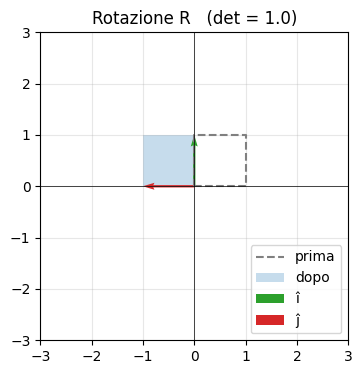

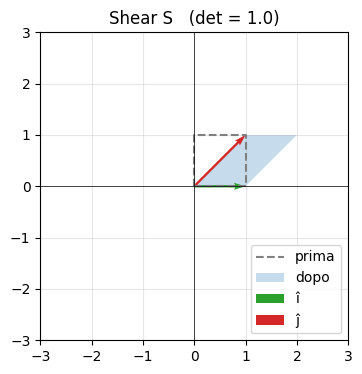

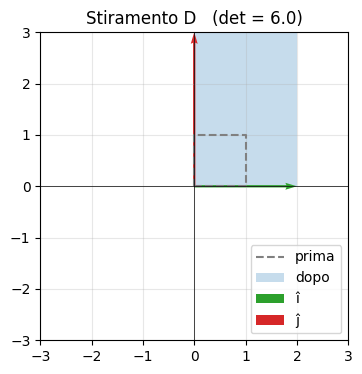

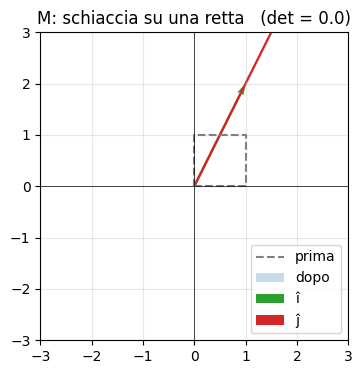

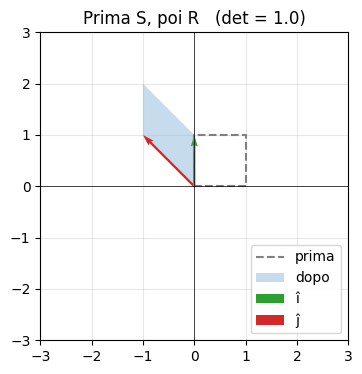

In [91]:
# Prova la funzione sulle matrici della settimana
if R is None or S is None:
    print("⏳ prima completa R e S nell'esercizio 2")
else:
    disegna(R, "Rotazione R")
    disegna(S, "Shear S")
    disegna(D, "Stiramento D")
    disegna(M, "M: schiaccia su una retta")
    disegna(R @ S, "Prima S, poi R")

**Sfida finale (senza controllo):** inventa una matrice con determinante negativo e disegnala.
Cosa succede all'orientamento di î e ĵ? Scrivi la risposta in una cella Markdown qui sotto.

---
**Consegna della settimana:** carica questo notebook su GitHub in un repository `ml-roadmap`
(cartella `fase1/settimana1`). Sarà il primo pezzo del tuo portfolio.

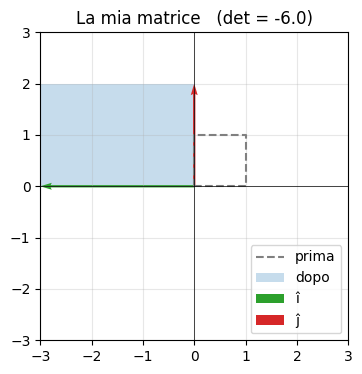

In [93]:
# La tua matrice con determinante negativo
T_mia = np.array([[-3,0],
                 [0,2]])
if T_mia is not None:
    disegna(T_mia, "La mia matrice")

### Cambia il verso di i_hat e viene allungato di una costante 3, mentre j_hat viene solo allungato di 2.